(1128, 3)
count    1128.000000
mean       -3.050102
std         2.096441
min       -11.600000
25%        -4.317500
50%        -2.860000
75%        -1.600000
max         1.580000
Name: logS, dtype: float64
1128
['smiles', 'logS', 'mol']
smiles    0
logS      0
mol       0
dtype: int64
0


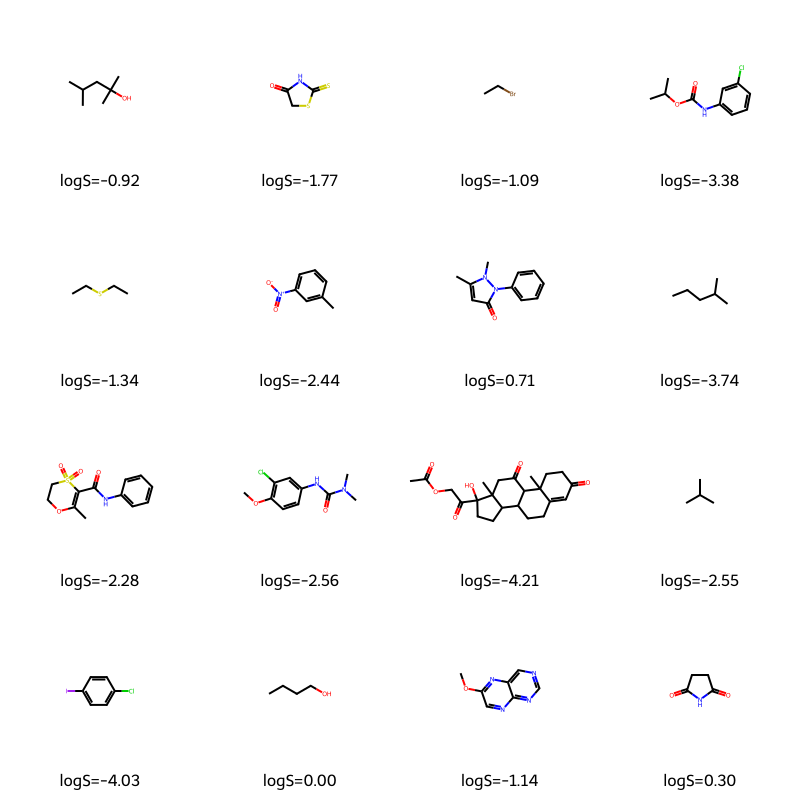

In [2]:
from Solubility import load_data, explore
from IPython.display import Image

df = load_data()
explore(df)

print(len(df))          # expect about 1,100 (the ESOL/Delaney set has 1,128)
print(df.columns.tolist())
print(df.isna().sum())  # missing values per column
print(df.duplicated().sum())  # duplicate rows
df.head()

df["logS"].describe()


Image("sample_molecules.png")

In [3]:
import numpy as np
import pandas as pd
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors
from Solubility import load_data, SEED

df = load_data()

def featurize(mol):
    heavy = mol.GetNumHeavyAtoms()
    aromatic = sum(a.GetIsAromatic() for a in mol.GetAtoms())
    return {
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Crippen.MolLogP(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "RotBonds": Lipinski.NumRotatableBonds(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "AromProp": aromatic / heavy if heavy else 0.0,
    }

X = pd.DataFrame([featurize(m) for m in df["mol"]])
y = df["logS"]
X.describe()

,MolWt,LogP,HBD,HBA,RotBonds,TPSA,AromProp
count,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000
mean,203.937074,2.447520,0.701241,2.069149,2.177305,34.872881,0.363544
std,102.738077,1.852875,1.089727,2.109388,2.640974,35.383593,0.343778
min,16.043000,-7.571400,0.000000,0.000000,0.000000,0.000000,0.000000
25%,121.183000,1.414900,0.000000,0.000000,0.000000,0.000000,0.000000
50%,182.179000,2.339000,0.000000,2.000000,1.000000,26.300000,0.375000
75%,270.372000,3.402200,1.000000,3.000000,3.000000,55.440000,0.666667
max,780.949000,10.388600,11.000000,16.000000,23.000000,268.680000,1.000000


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

def evaluate(model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    return np.sqrt(mean_squared_error(y_te, pred)), r2_score(y_te, pred)

models = {
    "Predict the mean": DummyRegressor(),
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(n_estimators=300, random_state=SEED),
}

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)

rows = []
for name, model in models.items():
    rmse, r2 = evaluate(model, X_tr, X_te, y_tr, y_te)
    rows.append({"model": name, "split": "random", "RMSE": rmse, "R2": r2})
pd.DataFrame(rows)

,model,split,RMSE,R2
0,Predict the mean,random,2.174275,-0.000141
1,Linear regression,random,1.093352,0.747098
2,Random forest,random,0.817634,0.858567


In [5]:
from collections import defaultdict
from rdkit.Chem.Scaffolds import MurckoScaffold

def scaffold_split(mols, frac_train=0.8):
    groups = defaultdict(list)
    for i, m in enumerate(mols):
        groups[MurckoScaffold.MurckoScaffoldSmiles(mol=m)].append(i)
    ordered = sorted(groups.values(), key=lambda g: (len(g), g[0]), reverse=True)
    n_train = int(frac_train * len(mols))
    train_idx, test_idx = [], []
    for g in ordered:
        if len(train_idx) + len(g) <= n_train:
            train_idx.extend(g)
        else:
            test_idx.extend(g)
    return train_idx, test_idx

tr, te = scaffold_split(df["mol"].tolist())
print(len(tr), len(te))

for name, model in models.items():
    rmse, r2 = evaluate(model, X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te])
    rows.append({"model": name, "split": "scaffold", "RMSE": rmse, "R2": r2})

results = pd.DataFrame(rows)
results.round(3)

902 226


,model,split,RMSE,R2
0,Predict the mean,random,2.174,-0.000
1,Linear regression,random,1.093,0.747
2,Random forest,random,0.818,0.859
3,Predict the mean,scaffold,2.244,-0.199
4,Linear regression,scaffold,1.289,0.605
5,Random forest,scaffold,0.955,0.783


In [6]:
rf = models["Random forest"].fit(X_tr, y_tr)
pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

LogP        0.816697
MolWt       0.097478
TPSA        0.043531
AromProp    0.014646
RotBonds    0.011307
HBA         0.009898
HBD         0.006444
dtype: float64

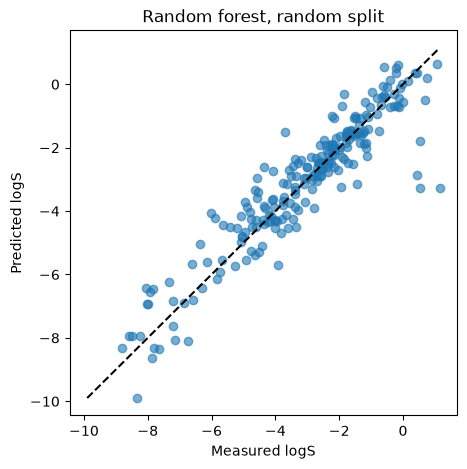

In [8]:
import matplotlib.pyplot as plt

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
rf = RandomForestRegressor(n_estimators=300, random_state=SEED).fit(X_tr, y_tr)
pred = rf.predict(X_te)

plt.figure(figsize=(5, 5))
plt.scatter(y_te, pred, alpha=0.6)
lims = [min(y_te.min(), pred.min()), max(y_te.max(), pred.max())]
plt.plot(lims, lims, "k--")
plt.xlabel("Measured logS")
plt.ylabel("Predicted logS")
plt.title("Random forest, random split")
plt.savefig("predicted_vs_measured.png", dpi=150, bbox_inches="tight")
plt.show()

results.round(3).to_csv("results.csv", index=False)

In [9]:
errors = pd.DataFrame({
    "smiles": df.loc[y_te.index, "smiles"],
    "measured": y_te,
    "predicted": pred,
})
errors["abs_error"] = (errors["measured"] - errors["predicted"]).abs()
worst = errors.sort_values("abs_error", ascending=False).head(6)
worst.round(2)

,smiles,measured,predicted,abs_error
1064,CNC(=O)C(C)SCCSP(=O)(OC)(OC),1.14,-3.28,4.42
292,CCN(CC)C(=O)C(=CCOP(=O)(OC)OC)Cl,0.52,-3.27,3.79
796,CCOP(=O)(OCC)OCC,0.43,-2.86,3.29
758,COP(=O)(NC(C)=O)SC,0.54,-1.80,2.34
588,Cc3cc2nc1c(=O)[nH]c(=O)nc1n(CC(O)C(O)C(O)CO)c2...,-3.68,-1.49,2.19
963,Fc1cccc(F)c1C(=O)NC(=O)Nc2ccc(Cl)cc2,-6.02,-4.07,1.95


In [10]:
has_P = df["mol"].apply(lambda m: any(a.GetSymbol() == "P" for a in m.GetAtoms()))
print(has_P.sum(), "phosphorus molecules in the full dataset")

test_P = errors[has_P.loc[errors.index]]
print(len(test_P), "of them in the test set")
print("mean signed error (measured - predicted):", (test_P["measured"] - test_P["predicted"]).mean().round(2))
print("mean abs error, all test molecules:", errors["abs_error"].mean().round(2))
print("mean abs error, phosphorus only:  ", test_P["abs_error"].mean().round(2))

43 phosphorus molecules in the full dataset
8 of them in the test set
mean signed error (measured - predicted): 1.71
mean abs error, all test molecules: 0.56
mean abs error, phosphorus only:   1.94
